# GRZS v številkah / GRZS in numbers

**Letna statistika / Annual statistics**

**Za poročilo / Presentation guide:** začnite s povzetkom in smrtnimi izidi v razdelku 9, nato uporabite trend intervencij (3), starostni prerez (6) in po potrebi vrste akcij (5). / Start with the summary and death outcomes in section 9, then use intervention trends (3), the age snapshot (6), and action types (5) if relevant. Korelacije so raziskovalna priloga, ne glavno sporočilo / Correlations are an exploratory appendix, not the headline.

Ta zvezek ponuja ponovljive preglede javno objavljene statistike intervencij Gorske reševalne zveze Slovenije (GRZS). Podatki so **letni seštevki po reševalnih enotah**, ne zapisi posameznih nesreč; z njimi ni mogoče raziskovati okoliščin posameznega dogodka.

This notebook provides reproducible views of the Slovenian Mountain Rescue Association (GRZS) published intervention statistics. The data are **annual aggregates by rescue unit**, not records of individual incidents; they cannot be used to investigate the circumstances of a particular event.

**Vir / Source:** [GRZS – Statistika nesreč](https://www.grzs.si/resevanje/statistika-nesrec/). Podatki v zvezku so lokalna kopija `data/accidents.csv`; zvezek jih ne prenaša in ne osvežuje samodejno. / Data in this notebook are the local `data/accidents.csv` snapshot; the notebook does not fetch or update data.

**Pomembno / Important:** zadnje leto v datoteki je lahko nepopolno. GRZS pojasnjuje, da so vključene zaključene intervencije oziroma popolna poročila, zato tekoče leto ni nujno primerljivo s polnimi leti. Pred uporabo preverite stanje in poimenovanje kategorij pri viru. / The latest year in the file may be incomplete. GRZS explains that statistics include concluded interventions or complete reports, so the current year may not be comparable with full years. Check the source's latest data and category definitions before use.

## 1. Naložite podatke / Load the data

Jupyter zaženite iz korenske mape projekta ali mape `notebooks`; pot do CSV se poišče v trenutni mapi in njenih nadrejenih mapah. Namestitev: `python -m pip install -r requirements-notebook.txt`.

Start Jupyter from the project root or the `notebooks` folder; the CSV is located by searching the current directory and its parents. Install dependencies with `python -m pip install -r requirements-notebook.txt`.

In [1]:
import csv
import math
from statistics import median
from collections import defaultdict
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

COLORS = ["#2563eb", "#0d9488", "#d97706", "#9333ea", "#db2777", "#475569"]
plt.rcParams.update({
    "figure.facecolor": "#f8fafc", "axes.facecolor": "#f8fafc",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.labelcolor": "#475569", "text.color": "#0f172a",
    "xtick.color": "#64748b", "ytick.color": "#64748b",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlepad": 14, "lines.linewidth": 2.4,
    "figure.dpi": 120, "savefig.dpi": 180,
    "figure.constrained_layout.use": True,
})


def style_axes(ax, title, *, horizontal=False):
    ax.set_title(title, fontsize=11)
    ax.set_axisbelow(True)
    ax.grid(axis="x" if horizontal else "y", color="#e2e8f0", linewidth=0.8)
    ax.tick_params(length=0, pad=8)
    count_axis = ax.xaxis if horizontal else ax.yaxis
    count_axis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    count_axis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    if horizontal:
        ax.set_xlim(left=0)
        ax.margins(x=0.18)
    else:
        ax.set_ylim(bottom=0)


def style_years(ax):
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
    ax.axvspan(latest_year - 0.45, latest_year + 0.45, color="#d97706", alpha=0.12)
    ax.set_xlim(years[0] - 0.5, latest_year + 0.5)
    ax.set_xlabel("Leto / Year")


def trend_panels(series, title):
    series = sorted(series, key=lambda item: item[1][years.index(reference_year)], reverse=True)
    fig, axes = plt.subplots((len(series) + 1) // 2, 2, figsize=(12, 2.8 * ((len(series) + 1) // 2)), squeeze=False)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    for ax, (label, values, color) in zip(axes.flat, series):
        ax.fill_between(years, values, color=color, alpha=0.09)
        ax.plot(years, values, color=color, marker="o", markersize=3)
        style_axes(ax, label)
        style_years(ax)
    for ax in list(axes.flat)[len(series):]:
        ax.set_visible(False)
    fig.supxlabel("Ločene lestvice / Independent y-scales · Oranžno: zadnje leto, lahko nepopolno / Amber: latest year, possibly incomplete", fontsize=9)
    plt.show()

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "data" / "accidents.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "accidents.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Could not find data/accidents.csv. Open this notebook from the project checkout.")

with DATA_PATH.open(encoding="utf-8", newline="") as csv_file:
    reader = csv.DictReader(csv_file)
    required_columns = {"year", "section", "unit", "metric", "value"}
    if not required_columns.issubset(reader.fieldnames or []):
        raise ValueError(f"CSV must contain columns {sorted(required_columns)}")
    rows = [
        {
            "year": int(row["year"]),
            "section": row["section"],
            "unit": row["unit"],
            "metric": "osebe18do55Let" if row["section"] == "poskodovanecStarost" and row["metric"] == "otroci18do55Let" else row["metric"],
            "value": float(row["value"]),
        }
        for row in reader
    ]

if not rows:
    raise ValueError("The CSV contains no statistics.")
years = sorted({row["year"] for row in rows})
latest_year = years[-1]
reference_year = years[-2] if len(years) > 1 else latest_year
print(f"Loaded {len(rows):,} rows from {DATA_PATH}")

Loaded 14,652 rows from /Users/ajda/Source/Personal/GRZS-analiza/data/accidents.csv


## 2. Obseg, preverjanja in povzetek / Coverage, checks, and summary

Zneski spodaj so vsote objavljenih vrednosti po enotah znotraj kategorije. Kategorije iz različnih razdelkov niso nujno medsebojno izključujoče; ne seštevajte jih brez potrditve pri GRZS. / Totals below sum the published values across units within a category. Categories across sections are not necessarily mutually exclusive; do not add them together without confirmation from GRZS.

In [2]:
totals = defaultdict(float)
keys = []
for row in rows:
    key = (row["year"], row["section"], row["unit"], row["metric"])
    keys.append(key)
    if row["value"] < 0:
        raise ValueError(f"Unexpected negative value: {row}")
    totals[(row["year"], row["section"], row["metric"])] += row["value"]

print(f"Years / Leta: {years[0]}–{latest_year} ({len(years)} distinct years)")
print(f"Rescue units / Reševalne enote: {len({row['unit'] for row in rows})}")
print(f"Sections / Razdelki: {', '.join(sorted({row['section'] for row in rows}))}")
print(f"Duplicate year-section-unit-metric rows / Podvojene vrstice: {len(keys) - len(set(keys))}")
print(f"Latest year / Zadnje leto: {latest_year} — potentially incomplete / lahko nepopolno")
if len(years) > 1:
    print(f"Reference year / Primerjalno leto: {reference_year} — verify completeness at source / preverite popolnost pri viru")

completed = {year: totals.get((year, "intervencije", "zakljucene"), 0) for year in years}
if len(years) > 1 and completed[years[0]]:
    start, end = years[0], reference_year
    change = completed[end] - completed[start]
    percent = 100 * change / completed[start]
    print(
        f"Summary / Povzetek: completed interventions / zaključene intervencije "
        f"{start}→{end}: {completed[start]:,.0f}→{completed[end]:,.0f} "
        f"({change:+,.0f}; {percent:+.1f}%). This is a count trend, not a rate or explanation of cause. "
        f"/ To je trend števila, ne stopnja ali razlaga vzroka."
    )
else:
    print("Not enough comparable years for a trend / Ni dovolj primerljivih let za trend.")

if len(keys) != len(set(keys)):
    raise ValueError("Duplicate year-section-unit-metric rows found; inspect the source before analysis.")

Years / Leta: 2006–2026 (21 distinct years)
Rescue units / Reševalne enote: 18
Sections / Razdelki: akcijaTip, dejavnost, intervencije, poskodbaVrsta, poskodovanecStarost
Duplicate year-section-unit-metric rows / Podvojene vrstice: 0
Latest year / Zadnje leto: 2026 — potentially incomplete / lahko nepopolno
Reference year / Primerjalno leto: 2025 — verify completeness at source / preverite popolnost pri viru
Summary / Povzetek: completed interventions / zaključene intervencije 2006→2025: 292→658 (+366; +125.3%). This is a count trend, not a rate or explanation of cause. / To je trend števila, ne stopnja ali razlaga vzroka.


## 3. Intervencije po letih / Interventions by year

`zakljucene` pomeni zaključene, `obdelava` obdelavo, `vse` pa skupno objavljeno vrednost. Prikazujemo zaključene in skupne vrednosti ločeno; zadnje leto je označeno kot morebitno nepopolno. / `zakljucene` means concluded, `obdelava` means being processed, and `vse` is the published total. Concluded and total values are shown separately; the latest year is marked as potentially incomplete.

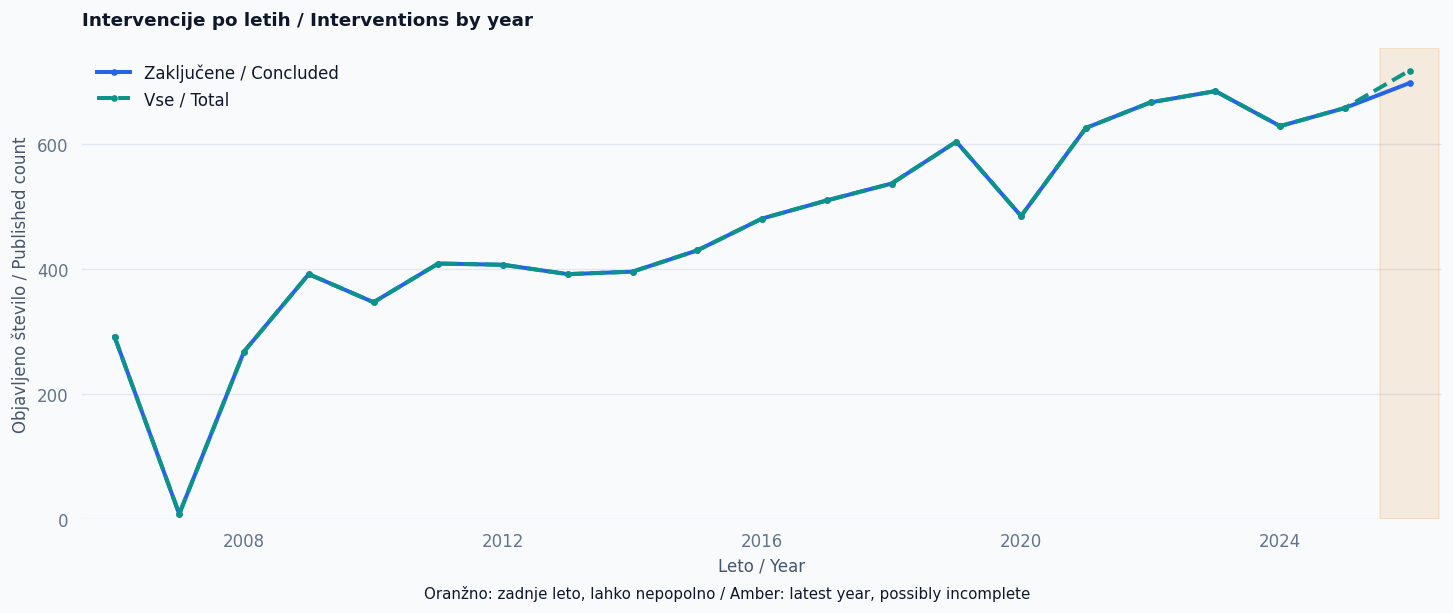

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
intervention_series = [
    ("Zaključene / Concluded", "zakljucene", COLORS[0], "-"),
    ("Vse / Total", "vse", COLORS[1], "--"),
]
intervention_series.sort(key=lambda item: totals[(reference_year, "intervencije", item[1])], reverse=True)
for label, metric, color, linestyle in intervention_series:
    ax.plot(years, [totals[(year, "intervencije", metric)] for year in years], color=color, linestyle=linestyle, marker="o", markersize=3, label=label)
style_axes(ax, "Intervencije po letih / Interventions by year")
style_years(ax)
ax.set_ylabel("Objavljeno število / Published count")
ax.legend(frameon=False, loc="upper left")
fig.supxlabel("Oranžno: zadnje leto, lahko nepopolno / Amber: latest year, possibly incomplete", fontsize=9)
plt.show()

## 4. Dejavnosti / Activities

Prikazane so dejavnosti z največjim seštevkom v vseh letih, ne deleži vseh intervencij. Ena intervencija se lahko pojavi v več kategorijah dejavnosti. / The chart shows activities with the largest sum across all years, not shares of all interventions. One intervention may appear in multiple activity categories.

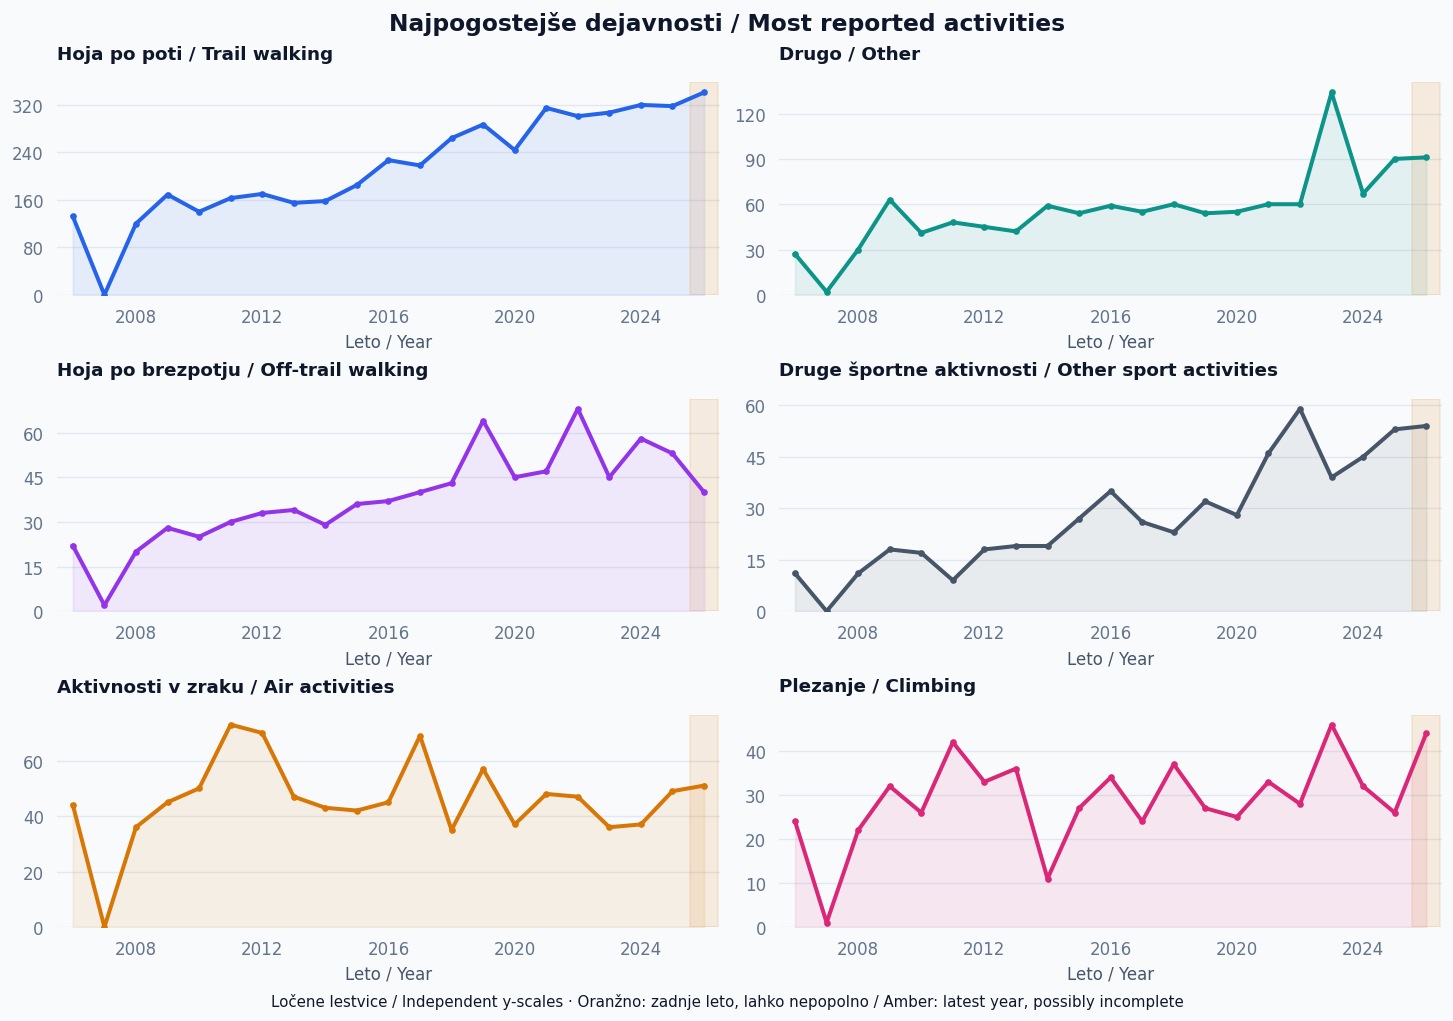

In [4]:
activity_metrics = sorted({row["metric"] for row in rows if row["section"] == "dejavnost"})
activity_totals = {
    metric: sum(totals.get((year, "dejavnost", metric), 0) for year in years)
    for metric in activity_metrics
}
top_activities = sorted(activity_metrics, key=activity_totals.get, reverse=True)[:6]
activity_labels = {
    "hojaPoPoti": "Hoja po poti / Trail walking",
    "hojaPoBrezpotju": "Hoja po brezpotju / Off-trail walking",
    "plezanje": "Plezanje / Climbing",
    "gorskoKolesarjenje": "Gorsko kolesarjenje / Mountain biking",
    "turnoSmucanje": "Turno smučanje / Ski touring",
    "alpskoSmucanje": "Alpsko smučanje / Alpine skiing",
    "aktivnostiVZraku": "Aktivnosti v zraku / Air activities",
    "delo": "Delo / Work", "drugo": "Drugo / Other",
    "vodneAktivnosti": "Vodne aktivnosti / Water activities",
    "drugeSportneRekreacijskeAktivnosti": "Druge športne aktivnosti / Other sport activities",
}
trend_panels([
    (activity_labels[metric], [totals.get((year, "dejavnost", metric), 0) for year in years], COLORS[index])
    for index, metric in enumerate(top_activities)
], "Najpogostejše dejavnosti / Most reported activities")

## 5. Vrste reševalnih akcij / Rescue-action categories

Polja iz izvornega razdelka `akcijaTip` so prikazana ločeno. `resevalcev` je objavljeno polje in ga ne smemo zamenjati s številom intervencij. Kategorije morda niso izključujoče. / Fields from the source section `akcijaTip` are shown separately. `resevalcev` is a published field and should not be mistaken for the number of interventions. Categories may overlap.

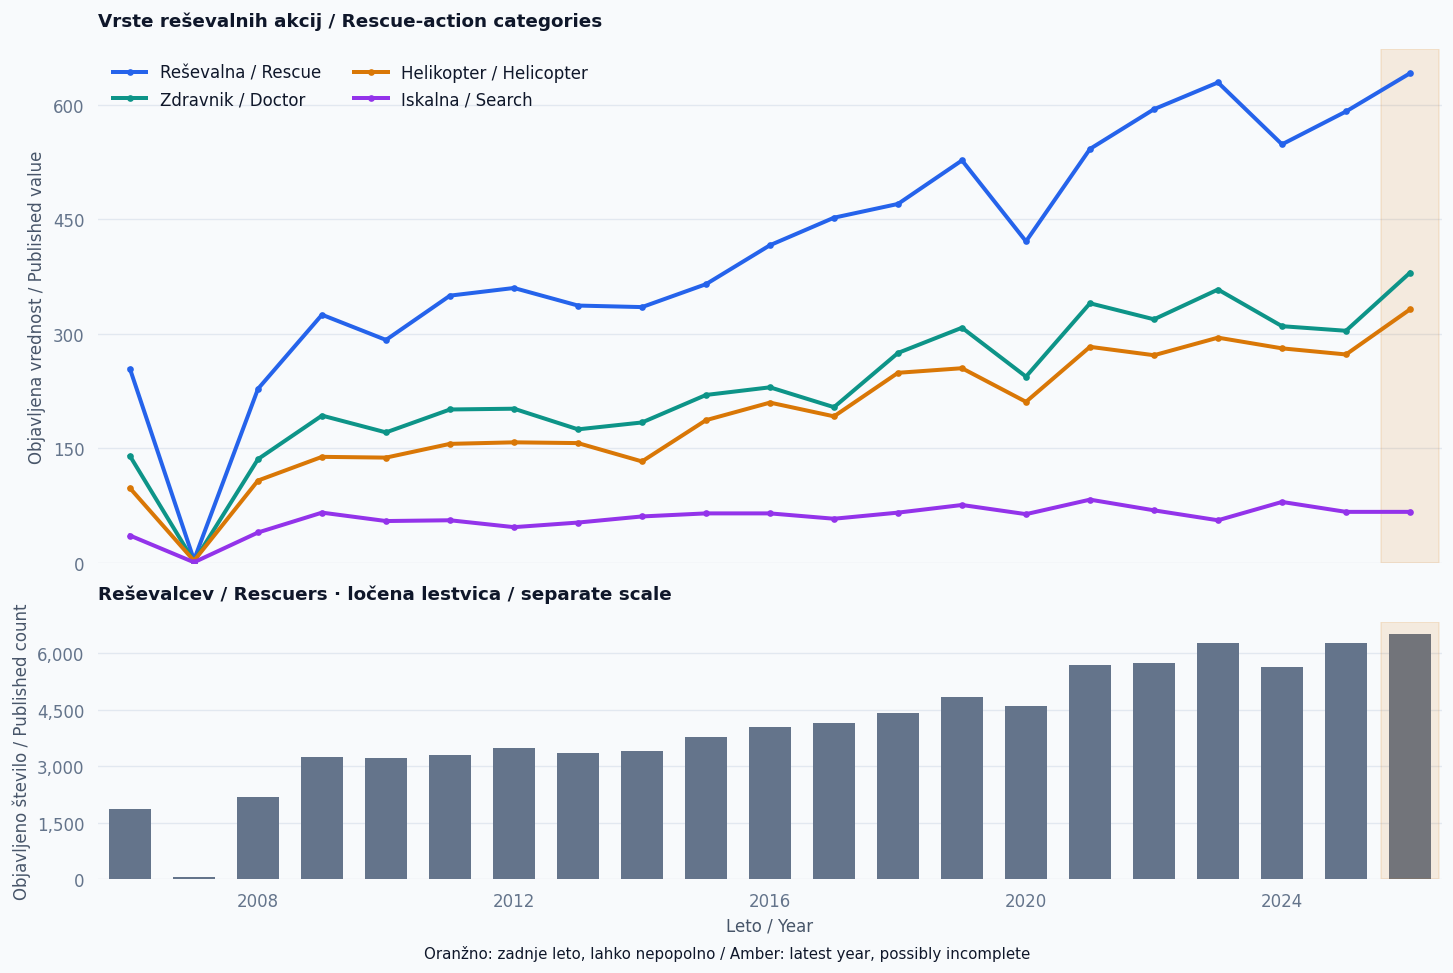

In [5]:
action_metrics = sorted({row["metric"] for row in rows if row["section"] == "akcijaTip"})
action_labels = {
    "helikopter": "Helikopter / Helicopter", "iskalna": "Iskalna / Search",
    "resevalna": "Reševalna / Rescue", "resevalcev": "Reševalcev / Rescuers (not interventions)",
    "zdravnik": "Zdravnik / Doctor",
}
action_order = sorted(
    (metric for metric in action_metrics if metric != "resevalcev"),
    key=lambda metric: totals[(reference_year, "akcijaTip", metric)], reverse=True,
)
fig, (action_ax, rescuer_ax) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[2, 1])
for index, metric in enumerate(action_order):
    action_ax.plot(years, [totals[(year, "akcijaTip", metric)] for year in years], color=COLORS[index % len(COLORS)], marker="o", markersize=3, label=action_labels[metric])
style_axes(action_ax, "Vrste reševalnih akcij / Rescue-action categories")
style_years(action_ax)
action_ax.set(xlabel="", ylabel="Objavljena vrednost / Published value")
action_ax.legend(frameon=False, loc="upper left", ncol=2)
rescuer_values = [totals[(year, "akcijaTip", "resevalcev")] for year in years]
rescuer_ax.bar(years, rescuer_values, color="#64748b", width=0.65)
style_axes(rescuer_ax, "Reševalcev / Rescuers · ločena lestvica / separate scale")
style_years(rescuer_ax)
rescuer_ax.set_ylabel("Objavljeno število / Published count")
fig.supxlabel("Oranžno: zadnje leto, lahko nepopolno / Amber: latest year, possibly incomplete", fontsize=9)
plt.show()

## 6. Vrste poškodb in starost / Outcomes and age groups

Razčlenitve prikazujejo objavljene kategorije, brez sklepanja o vzroku. / These breakdowns show published categories without inferring cause.

**Starost / Age:** mlajši / younger = `otrociPod10Let` + `otroci10do18Let`; odrasli / adults = `osebe18do55Let`; starejši / older = `osebe55do70Let` + `nad70Let`. Neznana starost / unknown age (`niPodatka`) ostane ločena / remains separate. Izvorno polje `otroci18do55Let` je preimenovano v `osebe18do55Let`, brez spremembe vrednosti / The original adult field is renamed without changing values.

Točne razmejitve pri 18 in 55 letih določa vir; iz agregatov jih ne moremo prerazporediti. Deleži vključujejo neznano starost; niso deleži intervencij ali stopnje tveganja. / Exact assignment at ages 18 and 55 follows the source and cannot be changed from aggregates. Percentages include unknown ages; they are not shares of interventions or risk rates. Kategorije so urejene padajoče po primerjalnem letu / Categories are ordered largest-first by reference-year value.

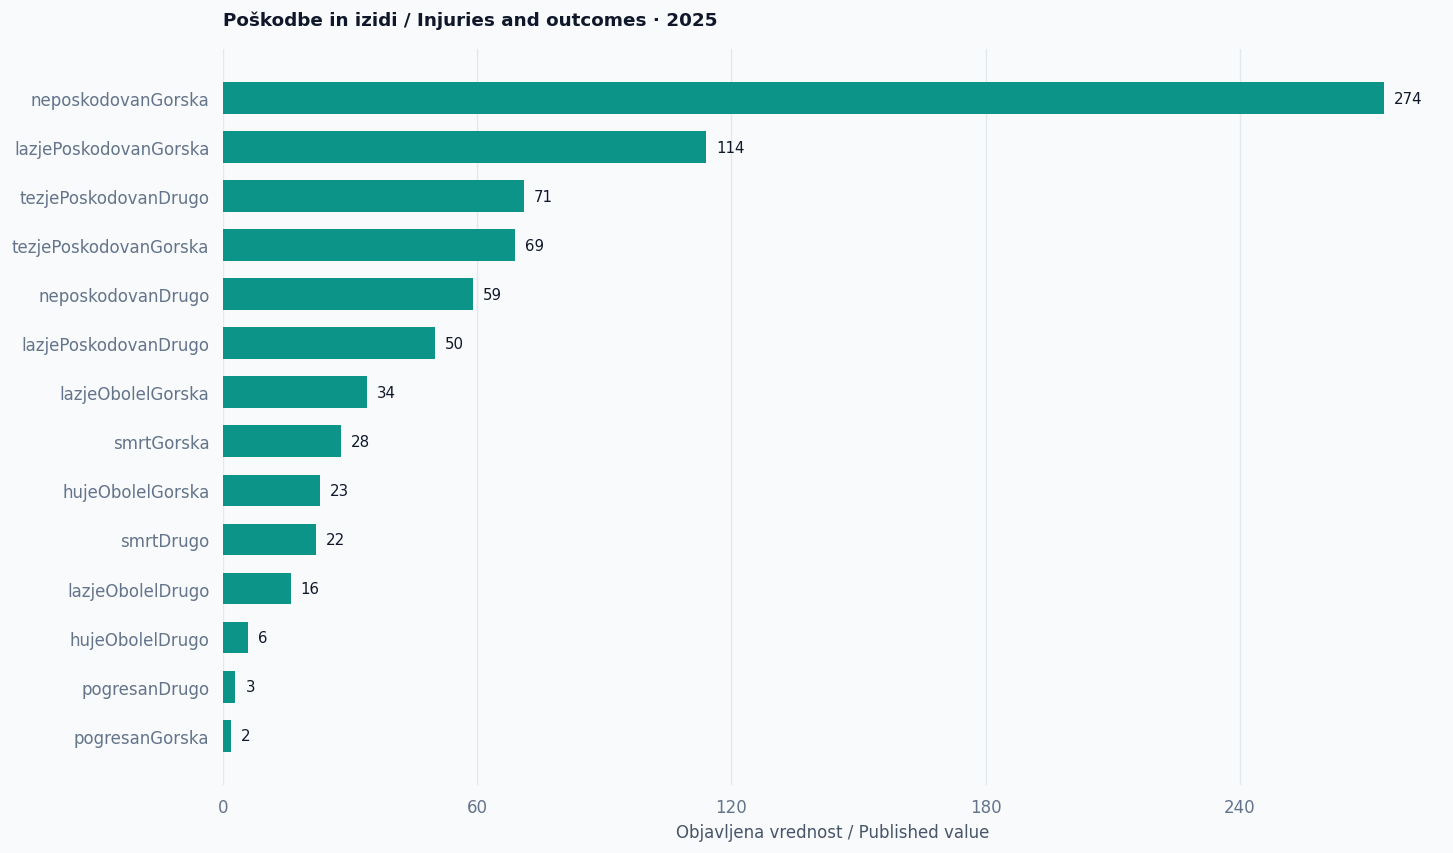

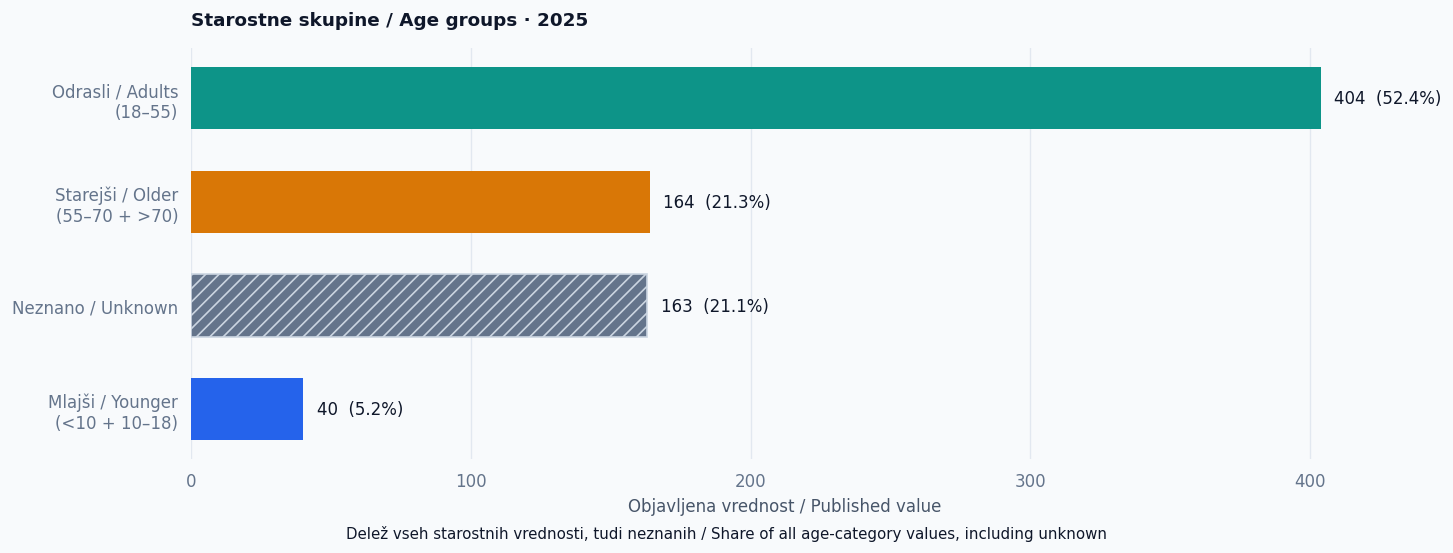

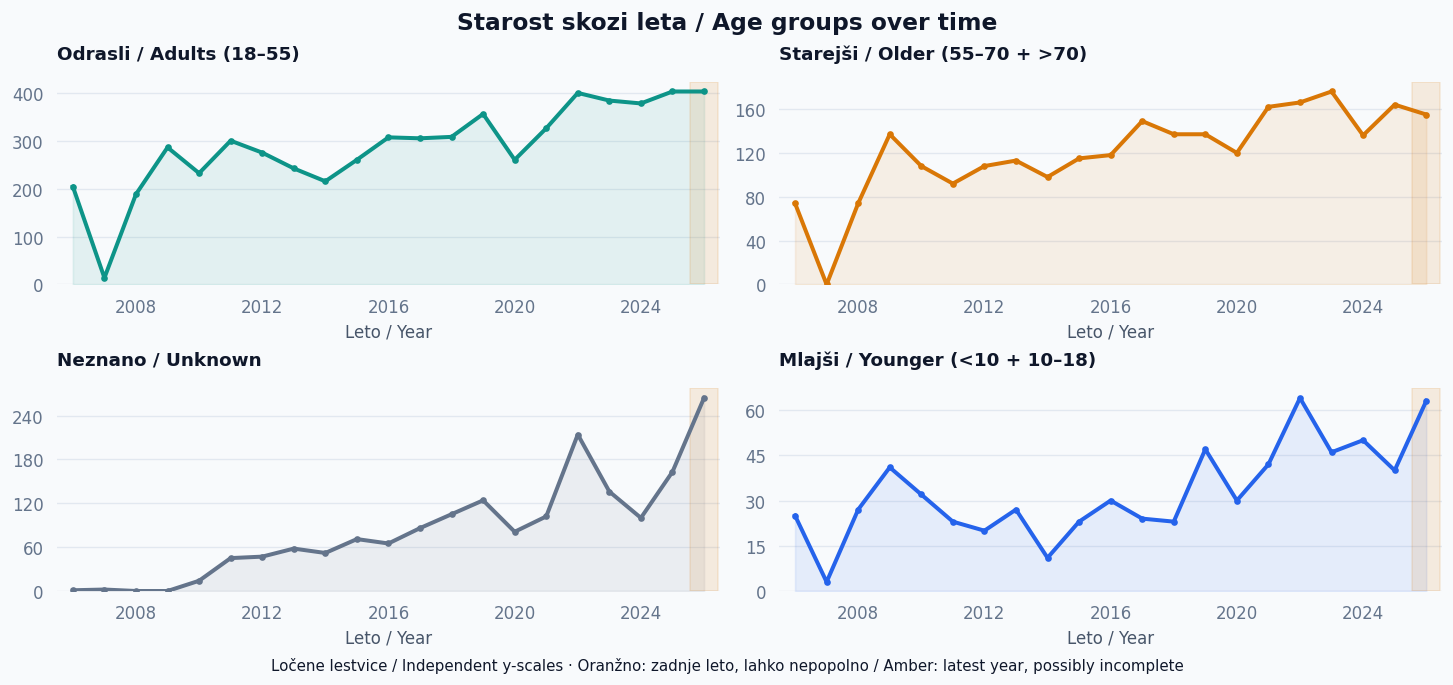

In [6]:
outcome_metrics = sorted({row["metric"] for row in rows if row["section"] == "poskodbaVrsta"})
outcome_totals = {metric: totals.get((reference_year, "poskodbaVrsta", metric), 0) for metric in outcome_metrics}
ordered_outcomes = sorted(outcome_metrics, key=outcome_totals.get, reverse=True)
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(ordered_outcomes, [outcome_totals[metric] for metric in ordered_outcomes], color=COLORS[1], height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt="{:,.0f}", padding=6, fontsize=9)
style_axes(ax, f"Poškodbe in izidi / Injuries and outcomes · {reference_year}", horizontal=True)
ax.set_xlabel("Objavljena vrednost / Published value")
plt.show()

age_groups = {
    "Mlajši / Younger\n(<10 + 10–18)": ("otrociPod10Let", "otroci10do18Let"),
    "Odrasli / Adults\n(18–55)": ("osebe18do55Let",),
    "Starejši / Older\n(55–70 + >70)": ("osebe55do70Let", "nad70Let"),
    "Neznano / Unknown": ("niPodatka",),
}
age_metrics = {row["metric"] for row in rows if row["section"] == "poskodovanecStarost"}
expected_age_metrics = {metric for metrics in age_groups.values() for metric in metrics}
if age_metrics != expected_age_metrics:
    raise ValueError(f"Age fields changed; review grouping. Missing: {expected_age_metrics - age_metrics}; unexpected: {age_metrics - expected_age_metrics}")
age_values = {
    label: [sum(totals[(year, "poskodovanecStarost", metric)] for metric in metrics) for year in years]
    for label, metrics in age_groups.items()
}
age_colors = dict(zip(age_groups, [COLORS[0], COLORS[1], COLORS[2], "#64748b"]))
age_order = sorted(age_groups, key=lambda label: age_values[label][years.index(reference_year)], reverse=True)
reference_age_counts = [age_values[label][years.index(reference_year)] for label in age_order]
reference_age_total = sum(reference_age_counts)
if reference_age_total <= 0:
    raise ValueError(f"No age-category values available for {reference_year}.")
fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.barh(age_order, reference_age_counts, color=[age_colors[label] for label in age_order], height=0.6)
unknown_bar = bars[age_order.index("Neznano / Unknown")]
unknown_bar.set_hatch("///")
unknown_bar.set_edgecolor("#cbd5e1")
ax.bar_label(bars, labels=[f"{count:,.0f}  ({count / reference_age_total:.1%})" for count in reference_age_counts], padding=8)
ax.invert_yaxis()
style_axes(ax, f"Starostne skupine / Age groups · {reference_year}", horizontal=True)
ax.margins(x=0.32)
ax.set_xlabel("Objavljena vrednost / Published value")
fig.supxlabel("Delež vseh starostnih vrednosti, tudi neznanih / Share of all age-category values, including unknown", fontsize=9)
plt.show()
trend_panels([
    (label.replace("\n", " "), age_values[label], age_colors[label])
    for label in age_order
], "Starost skozi leta / Age groups over time")

## 7. Primerjava reševalnih enot / Comparing rescue units

Prikazanih je največ deset enot po objavljeni vrednosti `intervencije.vse` za primerjalno leto (leto pred zadnjim v datoteki). To ni lestvica kakovosti ali tveganja: enote pokrivajo različna območja, obseg obiskovalcev in okoliščine niso upoštevani, primerjalno leto pa je treba preveriti. / The chart shows up to ten units by the published `intervencije.vse` value for the reference year (the year before the latest in the file). This is not a ranking of performance or risk: units cover different areas, visitor exposure and circumstances are not accounted for, and the reference year should be verified.

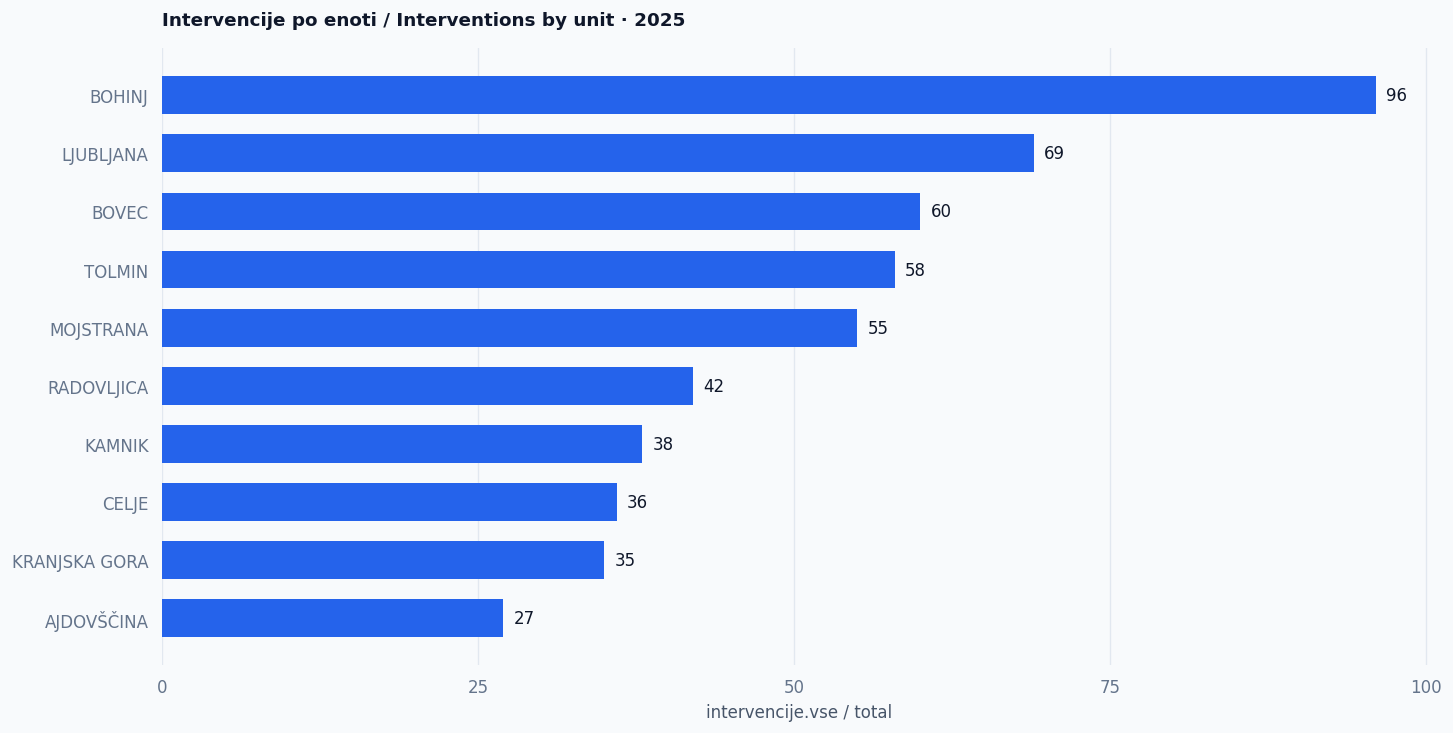

In [7]:
unit_totals = defaultdict(float)
for row in rows:
    if row["year"] == reference_year and row["section"] == "intervencije" and row["metric"] == "vse":
        unit_totals[row["unit"]] += row["value"]
top_units = sorted(unit_totals.items(), key=lambda item: item[1], reverse=True)[:10]
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh([fill(unit, 24) for unit, _ in top_units], [value for _, value in top_units], color=COLORS[0], height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt="{:,.0f}", padding=6)
style_axes(ax, f"Intervencije po enoti / Interventions by unit · {reference_year}", horizontal=True)
ax.set_xlabel("intervencije.vse / total")
plt.show()

## 8. Dolgoročna letna rast / Long-term annualized growth (CAGR)

CAGR = `(končna / začetna vrednost) ** (1 / število let) − 1`. Uporabimo zaključene intervencije od prvega leta do primerjalnega leta; zadnje, lahko nepopolno leto je izključeno. Popolnost drugih let preverite pri viru. / CAGR = `(end / start) ** (1 / elapsed years) − 1`. We use concluded interventions from the first year to the reference year, excluding the potentially incomplete latest year. Verify completeness of other years at the source.

Krivulja prikazuje enakomerno rast med končnima točkama, ne regresije ali napovedi. CAGR je občutljiv na izbiro začetnega in končnega leta ter skrije vmesna nihanja; ne meri tveganja in ne pojasni vzrokov. Pri ničelni začetni vrednosti ali brez dveh let izračun ni definiran. / The curve illustrates constant growth between endpoints, not a regression or forecast. CAGR is sensitive to endpoint selection and hides intermediate fluctuations; it measures neither risk nor causes. It is undefined with a zero starting value or fewer than two years.

CAGR 2006–2025: +4.37% / leto / year
292 → 658; 19 let / years. Zadnje leto izključeno / Latest year excluded.


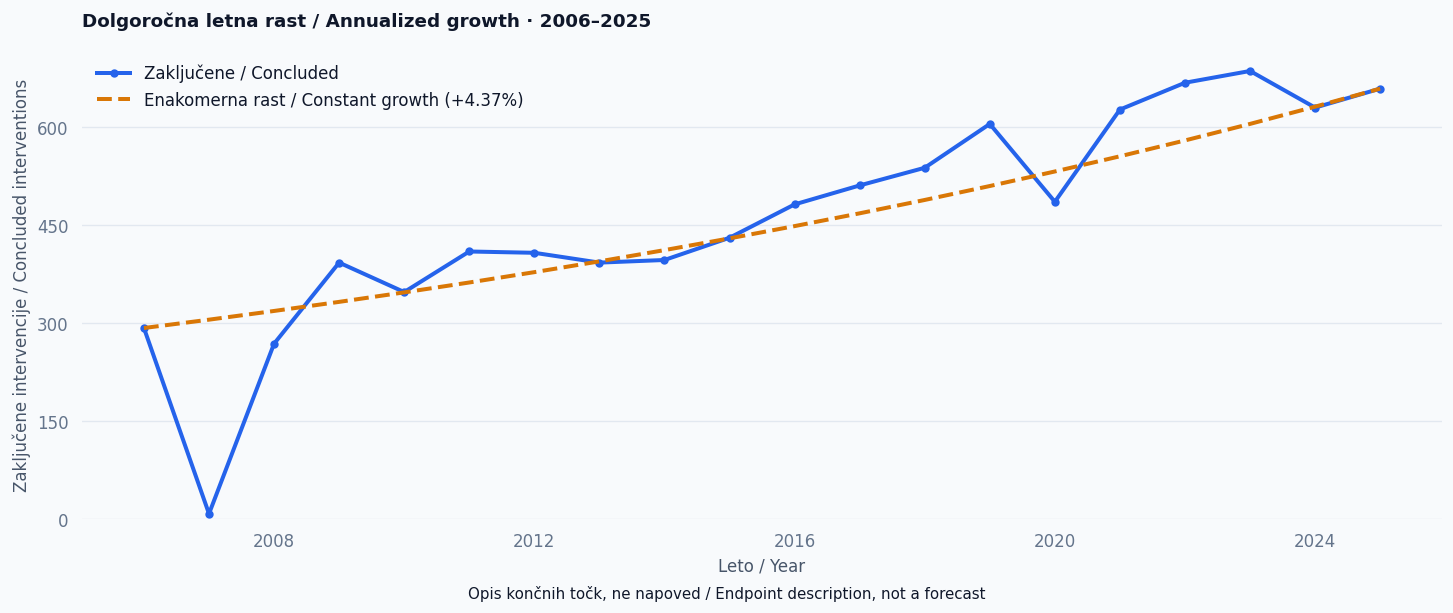

In [8]:
def calculate_cagr(start_value: float, end_value: float, start_year: int, end_year: int) -> float:
    if not math.isfinite(start_value) or not math.isfinite(end_value):
        raise ValueError("CAGR requires finite endpoint values.")
    if start_value <= 0 or end_value < 0 or end_year <= start_year:
        raise ValueError("CAGR requires a positive start, non-negative end, and a later end year.")
    return (end_value / start_value) ** (1 / (end_year - start_year)) - 1


cagr_years = [year for year in years if year < latest_year]
if len(cagr_years) < 2:
    raise ValueError("CAGR needs at least two years excluding the potentially incomplete latest year.")
cagr_start_year, cagr_end_year = cagr_years[0], cagr_years[-1]
cagr_counts = []
for year in cagr_years:
    key = (year, "intervencije", "zakljucene")
    if key not in totals:
        raise ValueError(f"Missing concluded-intervention values for {year}.")
    cagr_counts.append(totals[key])
intervention_cagr = calculate_cagr(cagr_counts[0], cagr_counts[-1], cagr_start_year, cagr_end_year)
print(f"CAGR {cagr_start_year}–{cagr_end_year}: {intervention_cagr:+.2%} / leto / year")
print(f"{cagr_counts[0]:,.0f} → {cagr_counts[-1]:,.0f}; {cagr_end_year - cagr_start_year} let / years. Zadnje leto izključeno / Latest year excluded.")
cagr_curve = [cagr_counts[0] * (1 + intervention_cagr) ** (year - cagr_start_year) for year in cagr_years]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cagr_years, cagr_counts, color=COLORS[0], marker="o", markersize=4, label="Zaključene / Concluded")
ax.plot(cagr_years, cagr_curve, color=COLORS[2], linestyle="--", label=f"Enakomerna rast / Constant growth ({intervention_cagr:+.2%})")
style_axes(ax, f"Dolgoročna letna rast / Annualized growth · {cagr_start_year}–{cagr_end_year}")
ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
ax.set(xlabel="Leto / Year", ylabel="Zaključene intervencije / Concluded interventions")
ax.legend(frameon=False)
fig.supxlabel("Opis končnih točk, ne napoved / Endpoint description, not a forecast", fontsize=9)
plt.show()

## 9. Povzetek za poročanje in smrtni izidi / Reporting summary and death outcomes

| Vprašanje / Question | Najboljši prikaz / Preferred chart | Zakaj / Why |
|---|---|---|
| Obseg reševanja / Rescue volume | Letni linijski graf (3) / Annual line chart | Časovni trend, ne tveganje / Trend, not risk |
| Smrtni izidi / Death outcomes | Dve poravnani časovni vrsti spodaj / Two aligned time series below | Ista lestvica, brez mešanja izvornih kategorij / Same scale, separate source categories |
| Starost in izidi / Age and outcomes | Urejeni vodoravni stolpci (6) / Ranked horizontal bars | Berljive oznake, tudi neznana starost / Readable labels, unknown ages visible |
| Vrste akcij / Action types | Linije in ločeni stolpci za reševalce (5) / Lines with separate rescuer bars | Različne merske enote / Different measures |
| Povezanost letnih števil / Association of annual counts | Raztros in preverjanje občutljivosti (10) / Scatterplots and sensitivity checks | Razkrije odstopanja, ne dokazuje vzrokov / Exposes outliers, not causes |

Dejavnosti, enote in CAGR so podporni prikazi, ne vsi hkrati na predstavitvi. Izogibamo se tortnim grafom prekrivajočih kategorij, dvojnim osem in lestvicam tveganja po enotah. / Activities, units and CAGR are supporting views, not all needed on a presentation slide. Avoid pie charts of overlapping categories, dual axes and unit risk rankings.

**Metodologija / Method:** `smrtGorska` in `smrtDrugo` ostaneta ločeni izvorni kategoriji. Ne seštevamo ju brez potrditve definicij. Ni individualnih povezav med starostjo, dejavnostjo in smrtnim izidom, niti podatkov o izpostavljenosti. / Death fields remain separate source categories; we do not sum them without verified definitions. No individual linkage between age, activity and death, or exposure data, is available. Zadnje leto je izključeno iz povzetka in korelacij / The latest year is excluded from summary comparisons and correlations.

POVZETEK / SUMMARY · 2025 (preverite popolnost / verify completeness)
Zaključene intervencije / Concluded interventions: 658
smrtGorska: 28; +5 glede na / versus 2024; mediana / median 2006–2025: 19
smrtDrugo: 22; +8 glede na / versus 2024; mediana / median 2006–2025: 15.5
CAGR zaključenih intervencij / Concluded-intervention CAGR: +4.37%; ne napoved / not a forecast
OPOZORILO / CAUTION: 2007 contains 8 concluded interventions in this snapshot; verify coverage, do not interpret as a confirmed fall in accidents.


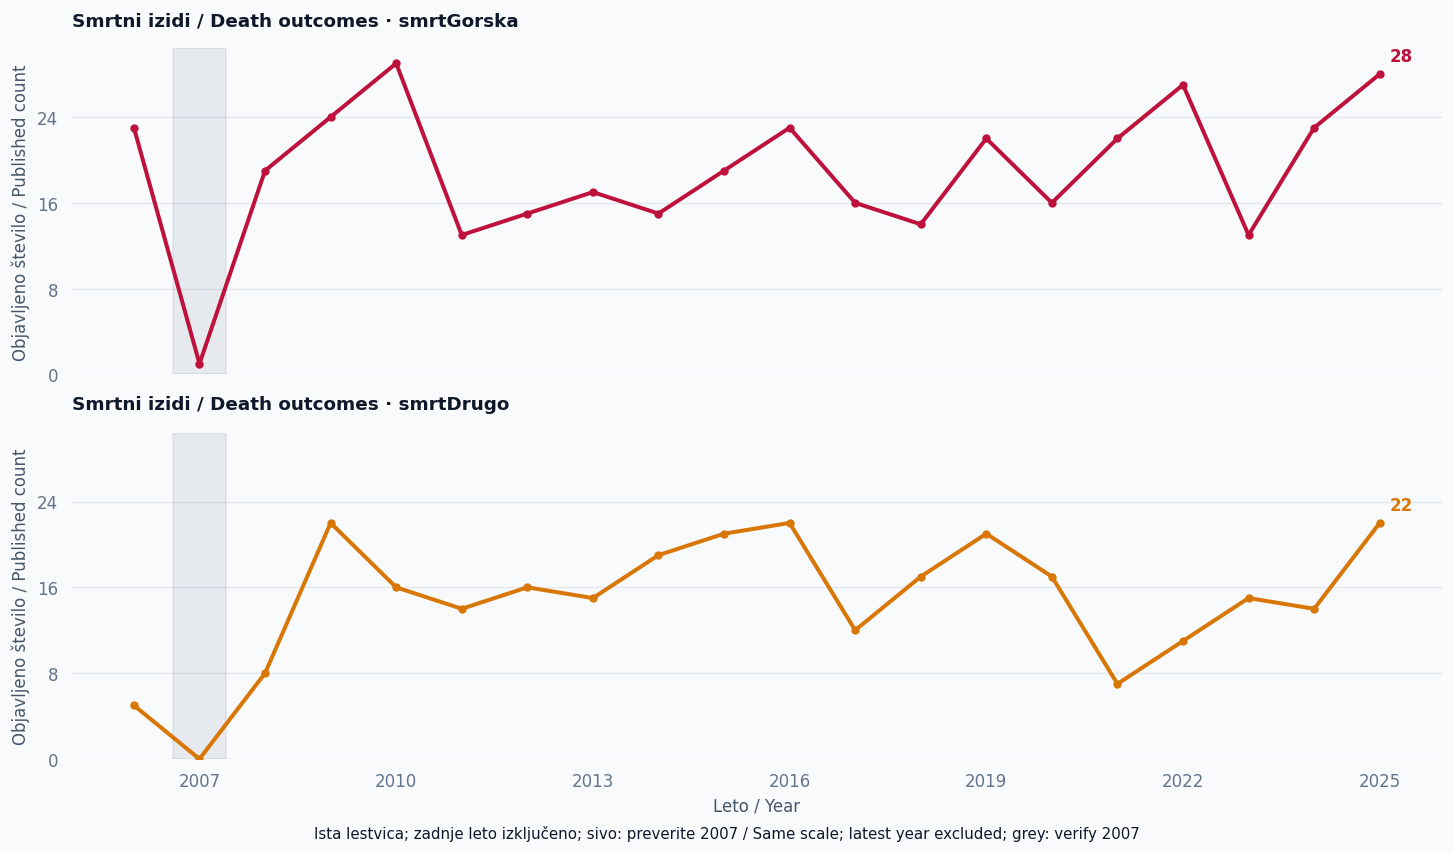

In [9]:
def annual_values(section, metric, selected_years):
    missing = [year for year in selected_years if (year, section, metric) not in totals]
    if missing:
        raise ValueError(f"Missing {section}.{metric} for years {missing}; do not treat as zero.")
    return [totals[(year, section, metric)] for year in selected_years]


report_years = [year for year in years if year < latest_year]
if len(report_years) < 3:
    raise ValueError("Reporting requires at least three years excluding the latest year.")
death_metrics = ("smrtGorska", "smrtDrugo")
death_series = {metric: annual_values("poskodbaVrsta", metric, report_years) for metric in death_metrics}
report_interventions = annual_values("intervencije", "zakljucene", report_years)
report_end = report_years[-1]
print(f"POVZETEK / SUMMARY · {report_end} (preverite popolnost / verify completeness)")
print(f"Zaključene intervencije / Concluded interventions: {report_interventions[-1]:,.0f}")
death_summary = {}
for metric, values in death_series.items():
    change = values[-1] - values[-2] if report_years[-1] - report_years[-2] == 1 else None
    death_summary[metric] = {"count": values[-1], "change": change, "median": median(values)}
    comparison = f"{change:+,.0f} glede na / versus {report_years[-2]}" if change is not None else "Ni zaporednih let / No consecutive-year comparison"
    print(f"{metric}: {values[-1]:,.0f}; {comparison}; mediana / median {report_years[0]}–{report_end}: {death_summary[metric]['median']:g}")
print(f"CAGR zaključenih intervencij / Concluded-intervention CAGR: {intervention_cagr:+.2%}; ne napoved / not a forecast")
if 2007 in report_years:
    print(f"OPOZORILO / CAUTION: 2007 contains {report_interventions[report_years.index(2007)]:g} concluded interventions in this snapshot; verify coverage, do not interpret as a confirmed fall in accidents.")
fig, death_axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, metric, color in zip(death_axes, death_metrics, ("#be123c", COLORS[2])):
    values = death_series[metric]
    ax.plot(report_years, values, color=color, marker="o", markersize=4)
    ax.annotate(f"{values[-1]:g}", (report_end, values[-1]), xytext=(6, 8), textcoords="offset points", color=color, fontweight="bold")
    style_axes(ax, f"Smrtni izidi / Death outcomes · {metric}")
    ax.set_ylabel("Objavljeno število / Published count")
    ax.margins(y=0.2)
    if 2007 in report_years:
        ax.axvspan(2006.6, 2007.4, color="#64748b", alpha=0.12)
death_axes[-1].xaxis.set_major_locator(MaxNLocator(nbins=7, integer=True))
death_axes[-1].xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
death_axes[-1].set_xlabel("Leto / Year")
fig.supxlabel("Ista lestvica; zadnje leto izključeno; sivo: preverite 2007 / Same scale; latest year excluded; grey: verify 2007", fontsize=9)
plt.show()

## 10. Raziskovalna priloga: korelacije / Exploratory appendix: correlations

Pearsonov **r** primerja letno število zaključenih intervencij z vsakim smrtnim poljem posebej. Prikazani so nivoji in **absolutne spremembe med zaporednima letoma**. Slednje zmanjšajo vpliv skupnega trenda, ne odpravijo pa vseh motenj ali časovne odvisnosti. / Pearson **r** compares annual concluded interventions with each death field separately. Both levels and **absolute changes between consecutive years** are shown. Changes reduce shared-trend effects but do not remove confounding or temporal dependence.

Tabela pokaže tudi občutljivost brez 2007, ki ima nenavadno nizke vrednosti. To ni dokaz napake in leto ostane v glavni analizi. Pri spremembah ne premostimo izpuščenega leta. / The table also shows sensitivity excluding unusually low-count 2007. This is not proof of an error; the year stays in the primary analysis. Changes never bridge a removed year.

**Ni vzročnosti ali individualnega tveganja / No causality or individual risk:** to niso korelacije med dejavnostjo ali starostjo posameznika in njegovo smrtjo. Več intervencij, poročanje in pokritost lahko vplivajo na obe števili. Ne podajamo p-vrednosti, napovedi ali zaključkov o učinkovitosti reševanja. / These are not individual activity/age–death correlations. Volume, reporting and coverage may affect both counts. No p-values, forecasts or conclusions about rescue effectiveness are provided. `n` pomeni leta oziroma pare zaporednih let / `n` denotes years or consecutive-year pairs.

smrtGorska   | Letna števila / Annual counts | r=+0.49, n=20 | brez / without 2007: r=+0.13, n=19
smrtGorska   | Spremembe / Changes        | r=+0.63, n=19 | brez / without 2007: r=+0.12, n=17
smrtDrugo    | Letna števila / Annual counts | r=+0.46, n=20 | brez / without 2007: r=+0.16, n=19
smrtDrugo    | Spremembe / Changes        | r=+0.40, n=19 | brez / without 2007: r=+0.23, n=17


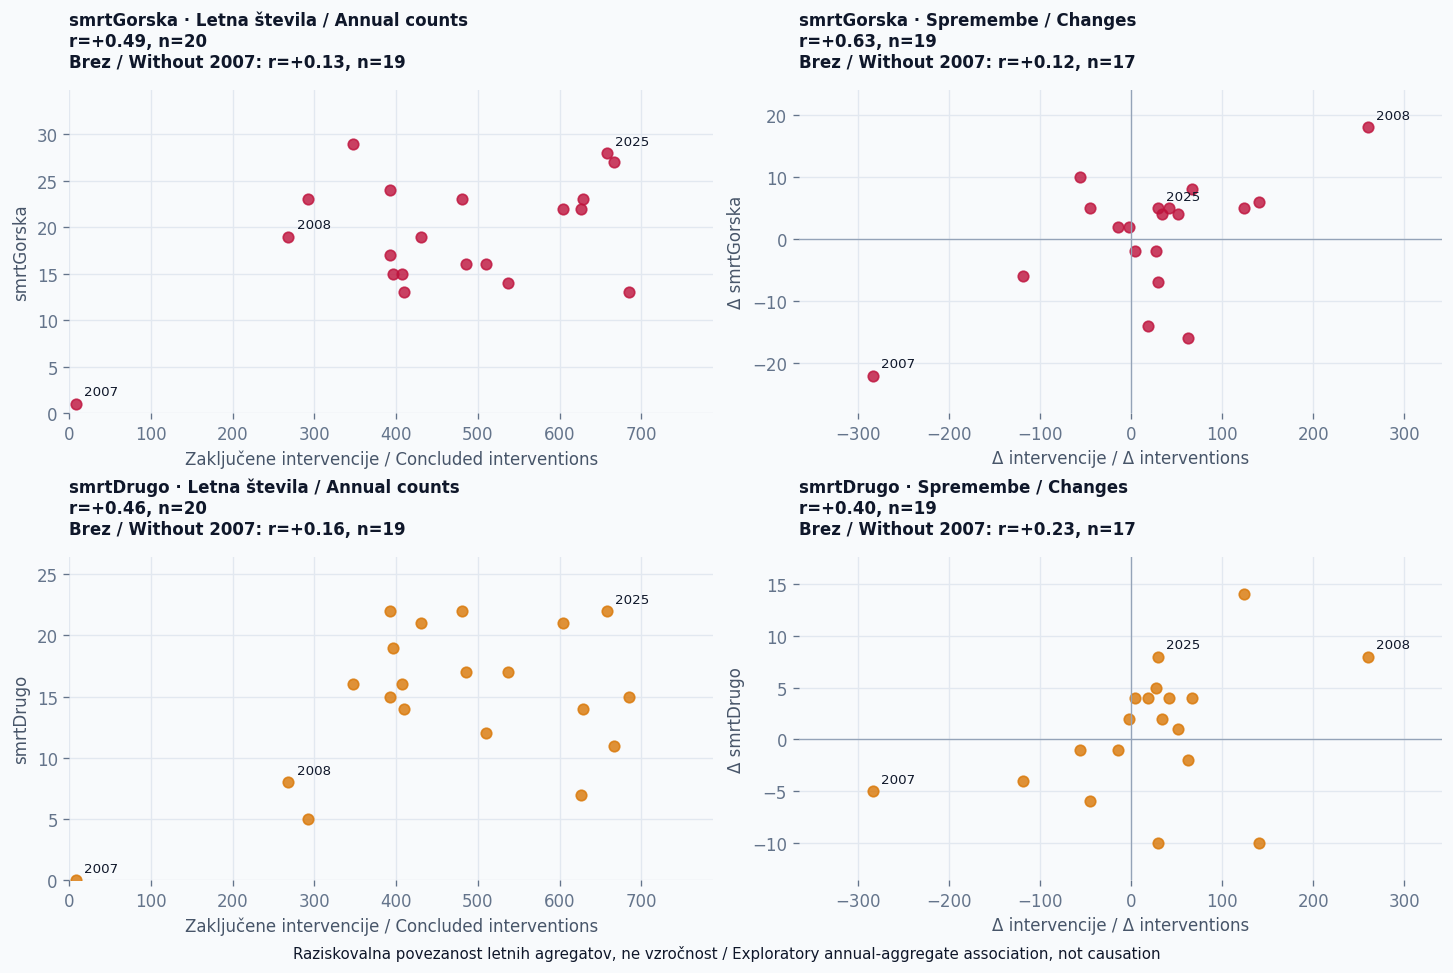

In [10]:
def pearson_r(x, y):
    if len(x) != len(y) or len(x) < 3:
        raise ValueError("Pearson r requires at least three aligned pairs.")
    if not all(math.isfinite(value) for value in [*x, *y]):
        raise ValueError("Pearson r requires finite values.")
    x_mean, y_mean = sum(x) / len(x), sum(y) / len(y)
    dx, dy = [value - x_mean for value in x], [value - y_mean for value in y]
    denominator = math.sqrt(sum(value ** 2 for value in dx) * sum(value ** 2 for value in dy))
    if denominator == 0:
        raise ValueError("Pearson r is undefined for a constant series.")
    return max(-1.0, min(1.0, sum(a * b for a, b in zip(dx, dy)) / denominator))


def correlation_pairs(selected_years, x, y, *, changes=False, excluded_years=()):
    if len(selected_years) != len(x) or len(x) != len(y):
        raise ValueError("Years and both series must align.")
    if any(b <= a for a, b in zip(selected_years, selected_years[1:])):
        raise ValueError("Years must be strictly increasing.")
    pairs = []
    for index, year in enumerate(selected_years):
        if year in excluded_years:
            continue
        if changes:
            if index == 0 or selected_years[index - 1] != year - 1 or year - 1 in excluded_years:
                continue
            pairs.append((year, x[index] - x[index - 1], y[index] - y[index - 1]))
        else:
            pairs.append((year, x[index], y[index]))
    return pairs


correlation_results = []
fig, correlation_axes = plt.subplots(2, 2, figsize=(12, 8))
for row_index, metric in enumerate(death_metrics):
    for column, changes in enumerate((False, True)):
        mode = "Spremembe / Changes" if changes else "Letna števila / Annual counts"
        pairs = correlation_pairs(report_years, report_interventions, death_series[metric], changes=changes)
        ax = correlation_axes[row_index, column]
        x, y = [pair[1] for pair in pairs], [pair[2] for pair in pairs]
        try:
            r = pearson_r(x, y)
        except ValueError as error:
            r = None
            print(f"{metric}, {mode}: {error}")
        result = {"metric": metric, "changes": changes, "pairs": pairs, "r": r}
        sensitivity = correlation_pairs(report_years, report_interventions, death_series[metric], changes=changes, excluded_years=(2007,))
        try:
            sensitivity_r = pearson_r([pair[1] for pair in sensitivity], [pair[2] for pair in sensitivity])
        except ValueError as error:
            sensitivity_r = None
            print(f"{metric}, {mode}, without 2007: {error}")
        result.update(sensitivity_r=sensitivity_r, sensitivity_pairs=sensitivity)
        correlation_results.append(result)
        r_label = f"{r:+.2f}" if r is not None else "undefined"
        sensitivity_label = f"{sensitivity_r:+.2f}" if sensitivity_r is not None else "undefined"
        print(f"{metric:12} | {mode:26} | r={r_label}, n={len(pairs)} | brez / without 2007: r={sensitivity_label}, n={len(sensitivity)}")
        ax.scatter(x, y, color=("#be123c", COLORS[2])[row_index], s=40, alpha=0.8)
        for year, x_value, y_value in pairs:
            if year in (2007, 2008, report_end):
                ax.annotate(str(year), (x_value, y_value), xytext=(5, 5), textcoords="offset points", fontsize=8)
        ax.set_title(f"{metric} · {mode}\nr={r_label}, n={len(pairs)}\nBrez / Without 2007: r={sensitivity_label}, n={len(sensitivity)}", fontsize=10)
        ax.set_xlabel("Δ intervencije / Δ interventions" if changes else "Zaključene intervencije / Concluded interventions")
        ax.set_ylabel(f"Δ {metric}" if changes else metric)
        ax.grid(color="#e2e8f0", linewidth=0.8)
        ax.set_axisbelow(True)
        if changes:
            ax.margins(x=0.15, y=0.15)
            ax.axhline(0, color="#94a3b8", linewidth=0.8)
            ax.axvline(0, color="#94a3b8", linewidth=0.8)
        else:
            ax.set(xlim=(0, max(x) * 1.15), ylim=(0, max(y) * 1.2))
fig.supxlabel("Raziskovalna povezanost letnih agregatov, ne vzročnost / Exploratory annual-aggregate association, not causation", fontsize=9)
plt.show()

## 11. Odgovorna uporaba / Responsible use

- **Povejte, kaj štejejo podatki:** letni agregati GRZS po enotah in kategorijah, ne posamezni primeri. / **Say what the data count:** annual GRZS aggregates by unit and category, not individual cases.
- **Preverite popolnost zadnjega leta** pri GRZS; primerjajte enako dolga obdobja ali izločite nepopolno leto. / **Verify the latest year's completeness** with GRZS; compare equal periods or exclude an incomplete year.
- **Ne sklepajte o vzrokih, tveganju ali uspešnosti** iz samih števil intervencij. Manjkajo imenovalci in okoliščine. / **Do not infer causes, risk, or performance** from intervention counts alone. Denominators and circumstances are missing.
- **Ne seštevajte kategorij kot neodvisnih dogodkov** brez potrditve, da se ne prekrivajo; preverite tudi definicije polj in morebitne spremembe metodologije pri viru. / **Do not add categories as independent events** unless their mutual exclusivity is confirmed; check field definitions and any methodology changes with the source.
- **Navedite vir in datum prenosa** (`data/accidents.csv` je posnetek), po potrebi pa delite izračun in graf za ponovljivost. / **Cite the source and retrieval date** (`data/accidents.csv` is a snapshot), and share the calculation and chart where useful for reproducibility.

Za osvežitev podatkov uporabite `python3 scripts/fetch_stats.py`; nato znova zaženite vse celice. / To refresh the data, run `python3 scripts/fetch_stats.py`, then rerun all cells.